# Control rápido por eventos: estado del arte

**Nivel:** 3  
**Requisitos previos:** Control rápido por eventos nivel 1  
**Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Cómo se compara una nueva ejecución de la mejor referencia aprendida con las políticas rápidas protegidas en esta observación C01 emparejada?


## Objetivos

Para el nivel 3 de control de eventos con guardas en C01, Explica cómo una observación de evento se convierte en una elección acotada. Para el nivel 3 de control de eventos con guardas en C01, La distinción central está entre ordenar un candidato registrado y otorgarle autoridad: Para el nivel 3 de control de eventos con guardas en C01, el entorno admite solo la acción cuyos herramienta, argumentos y revisión del recurso satisfacen el contrato.


## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
Para el nivel 3 de control de eventos con guardas en C01, El notebook lee artefactos comprometidos del producto. Para el nivel 3 de control de eventos con guardas en C01, Propietario: Para el nivel 3 de control de eventos con guardas en C01, Neuraxis. Para el nivel 3 de control de eventos con guardas en C01, Repositorio: Para el nivel 3 de control de eventos con guardas en C01, https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Para el nivel 3 de control de eventos con guardas en C01, Apache-2.0. Para el nivel 3 de control de eventos con guardas en C01, El JSON es un artefacto experimental propio y congelado; Para el nivel 3 de control de eventos con guardas en C01, este notebook no redistribuye datos de benchmarks externos.

Para el nivel 3 de control de eventos con guardas en C01, Este notebook lee `data/derived/index.json` y las trazas listadas. Para el nivel 3 de control de eventos con guardas en C01, La ejecución usa un espacio aislado de caso Reflexmesh. Para el nivel 3 de control de eventos con guardas en C01, Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta. Para el nivel 3 de control de eventos con guardas en C01, El manifiesto de publicación verifica los hashes. Para el nivel 3 de control de eventos con guardas en C01, M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado.

Para el nivel 3 de control de eventos con guardas en C01, Artefactos de esta lección:

- `data/derived/index.json`
- `data/derived/episodes/M01-C01-nominal-40000.json`
- `data/derived/episodes/M02-C01-nominal-40000.json`


## Método

Para el nivel 3 de control de eventos con guardas en C01, El conjunto de candidatos es el espacio de acciones de esta decisión, no de las siguientes. Para el nivel 3 de control de eventos con guardas en C01, Una regla o puntuación no puede agregar una capacidad ausente, omitir una revisión obsoleta ni reinterpretar texto de archivo no confiable como instrucción. Para el nivel 3 de control de eventos con guardas en C01, La FSM y el árbol de comportamiento son referencias implementadas por separado; Para el nivel 3 de control de eventos con guardas en C01, coincidir en una tarea breve no los convierte en el mismo algoritmo. Para el nivel 3 de control de eventos con guardas en C01, La traza sirve porque expone la observación exacta, los candidatos admisibles, la primera acción y el resultado del oráculo. Para el nivel 3 de control de eventos con guardas en C01, Su forma de un paso también limita lo que enseña: Para el nivel 3 de control de eventos con guardas en C01, no prueba recuperación tras eventos tardíos, carreras de cancelación, herramientas nuevas ni cambios de distribución. Para el nivel 3 de control de eventos con guardas en C01, Esos mecanismos requieren casos y resultados independientes. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, La máscara de admisibilidad define las acciones que el entorno puede ejecutar con seguridad. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, la puntuación solo ordena ese conjunto y no crea capacidades ni invalida una revisión obsoleta del recurso. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, El controlador de estados finitos ofrece una referencia inferior útil porque sus reglas son inspeccionables y deterministas. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, un árbol de comportamiento expresa la tarea con guardas y alternativas explícitas. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, Una prueba de estrés relevante cambia el tiempo del evento o la disponibilidad de candidatos sin alterar el contrato, y verifica la poscondición en vez de comparar solo la primera acción. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, Lee la traza como observación, conjunto admisible, acción elegida y resultado de un oráculo independiente. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, unir esos campos en una sola etiqueta de éxito oculta el origen de la autoridad. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, La coincidencia en un caso solo demuestra consistencia local. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, la robustez requiere semillas y perturbaciones independientes que revelen estados obsoletos, candidatos ausentes y efectos no autorizados. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, En este nivel, informa si cada acción elegida permanece dentro del contrato declarado de herramienta y recurso. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, distingue una negativa segura de un fallo de tarea en la tabla. Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, para control de eventos con guardas en C01, Una extensión útil cambia un orden de eventos por vez, conserva el oráculo del caso y registra qué transición produjo la divergencia para reproducir la respuesta.


### control de eventos con guardas · nivel 3 — Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.


In [2]:
# Carga las trazas propias y verifica sus hashes; nunca modifica los artefactos canónicos.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M01", "M02"]
trace_methods = ["M01", "M02", "M04"]
sample_case = "C01"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Trazas verificadas por hash:", len(records))


Trazas verificadas por hash: 3


### control de eventos con guardas · nivel 3 — Ejecuta las políticas publicadas y compara la corrida


### control de eventos con guardas · nivel 3 — Compara la secuencia completa y no solo la primera acción


### control de eventos con guardas · nivel 3 — Recalcula resultados por variante desde todas las trazas del caso


In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "éxitos=",
        sum(values),
        "episodios=",
        len(values),
        "tasa=",
        round(sum(values) / len(values), 3),
    )


M01 boundary éxitos= 10 episodios= 10 tasa= 1.0
M01 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M01 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M01 nominal éxitos= 10 episodios= 10 tasa= 1.0
M01 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M01 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M02 boundary éxitos= 10 episodios= 10 tasa= 1.0
M02 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M02 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M02 nominal éxitos= 10 episodios= 10 tasa= 1.0
M02 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M02 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0


### control de eventos con guardas · nivel 3 — Visualiza el estrés por variante sin mezclar familias


In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
display(fig)
plt.close(fig)


<Figure size 900x450 with 1 Axes>

### control de eventos con guardas · L3 — Construir la primera política ejecutable

En el nivel 3, construye M01 para control de eventos con guardas con la fábrica pública y conserva su contrato de observación antes de muestrear C01.


In [5]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M01


### control de eventos con guardas · L3 — Ejecutar el método principal en el caso indicado

En el nivel 3 de control de eventos con guardas, el evaluador ejecuta M01 en C01 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [6]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### control de eventos con guardas · L3 — Construir una política de comparación independiente

Para el nivel 3 de control de eventos con guardas, crea M02 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación.


In [7]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M02"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M02


### control de eventos con guardas · L3 — Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 3 ejecuta M02 en el mismo C01, variante nominal y semilla, and ilustra comportamiento, no estima una tasa poblacional.


In [8]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### control de eventos con guardas · L3 — Agregar los dos episodios ejecutados

En el nivel 3, el agregador resume dos episodios ejecutados de control de eventos con guardas, and las afirmaciones entre familias aún requieren el benchmark completo.


In [9]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### control de eventos con guardas · L3 — Resultados de políticas nuevas

Para el nivel 3 de control de eventos con guardas en C01, El gráfico siguiente se calcula con los resultados de episodios de control de eventos con guardas recién ejecutados en C01, no se copia de un artefacto congelado.


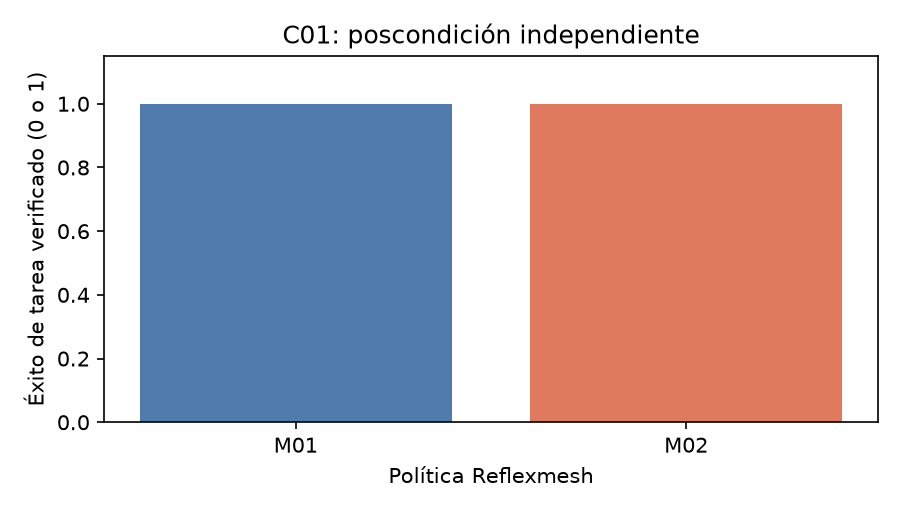

In [10]:
# Grafica los resultados verificados independientemente de las dos ejecuciones nuevas.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para el nivel 3 de control de eventos con guardas en C01, Para control de eventos con guardas, estas barras muestran resultados nuevos de poscondición de M01 y M02 en C01; Para el nivel 3 de control de eventos con guardas en C01, éxito vale 1 y falla 0. Para el nivel 3 de control de eventos con guardas en C01, Lee el caso y la semilla antes de compararlas. Para el nivel 3 de control de eventos con guardas en C01, Este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software.


## Estado del arte

En el nivel 3, para control de eventos con guardas en C01, La comparación se sitúa frente a decisiones rápidas tipadas, arbitraje entre control model-free y model-based y agentes asíncronos que combinan código y modelos de lenguaje. En el nivel 3, para control de eventos con guardas en C01, Estas fuentes establecen diseños previos y preguntas experimentales, no evidencia independiente de que Neuraxis sea un Sistema Uno biológico ni de que un broker tipado sea novedoso. En el nivel 3, para control de eventos con guardas en C01, La referencia empírica aquí es M04 en el mismo caso, mientras M01 sigue siendo la regla medida más fuerte del núcleo. En el nivel 3, para control de eventos con guardas en C01, Se distingue deliberadamente el arte previo de un ganador interno del benchmark.


### control de eventos con guardas · L3 — Ejecutar la referencia XGBoost bajo condiciones emparejadas

Esta llamada de referencia del nivel 3 para control de eventos con guardas ejecuta M04 en C01 con la misma semilla nominal, y su resultado y tiempo forman una observación emparejada.


In [11]:
# Ejecuta la política XGBoost medida con la misma especificación del caso.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Ejecuciones de la referencia del estado del arte:", 1)
print("Éxito de tarea de XGBoost:", state_art_result["metrics"]["task_success"])


Ejecuciones de la referencia del estado del arte: 1
Éxito de tarea de XGBoost: 1


### control de eventos con guardas · L3 | Tiempo registrado del controlador

En el nivel 3, la figura de tiempos de control de eventos con guardas usa registros congelados y verificados por hash para M01 y M04 en C01, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 3 para control de eventos con guardas describe el entorno registrado bajo su caso, variante y semilla declarados.

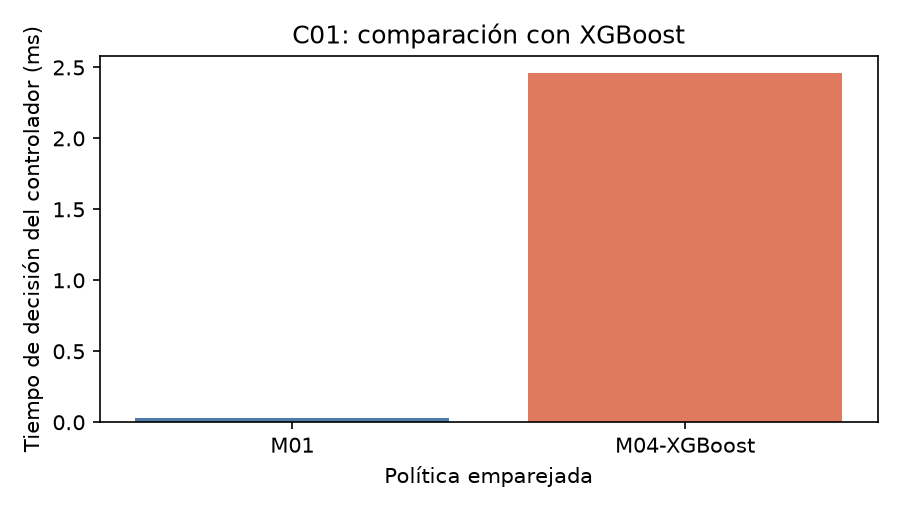

In [12]:
# Compara tiempos canónicos del controlador, verificados por hash, bajo el mismo caso, variante y semilla.
labels = [primary_id, "M04-XGBoost"]
latencies = [records[primary_id]["metrics"]["controller_ms"], records["M04"]["metrics"]["controller_ms"]]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Tiempo de decisión del controlador (ms)")
ax.set_xlabel("Política emparejada")
ax.set_title(f"{sample_case}: comparación con XGBoost")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 3 para control de eventos con guardas lee registros canónicos de M01/M04 en C01, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. En esta lección de control de eventos con guardas, el gráfico estable describe la latencia registrada y no afirma rapidez en la máquina actual.

## Resultados

**Respuesta:** La comparación de nivel 3 para control de eventos con guardas contiene 2 episodios nuevos y 1 referencia XGBoost M04 en C01; esas 3 corridas emparejadas no establecen superioridad poblacional para control de eventos con guardas.

Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Esta repetición con el paquete comprueba una decisión protegida exacta sobre la misma observación congelada. Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, No demuestra transferencia general, un mecanismo biológico ni superioridad frente a un sistema desplegado y emparejado.

Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Este paso de autoría no compromete salidas generadas; Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, Para el nivel 3 de control de eventos con guardas en C01, `scripts/run_notebooks.py` las ejecuta y guarda desde un kernel nuevo.


## Resumen

Para el nivel 3 de control de eventos con guardas en C01, En el nivel 3, control de eventos con guardas usa C01 para mostrar el comportamiento del método publicado bajo una condición declarada. Para el nivel 3 de control de eventos con guardas en C01, Mantén el resultado observado separado de una afirmación sobre inteligencia general para controlar software.


## Referencias

- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev)
- [LEE](https://doi.org/10.1016/j.neuron.2013.11.028)
- [DPT](https://aclanthology.org/2025.acl-long.206/)
